# Onafhankelijke E2-schaal vast na epoch 50
## Voortzetting tot epoch 100 · CNN-8 / SVHN · E4M3 → E2M3 → E2M1 · A32 · B32

**Onderzoeksvraag:** wat verandert wanneer we vanaf hetzelfde checkpoint van epoch 50 stoppen met het leren van de absolute E2-schaal en de gewichten verder trainen tot epoch 100?

De run herstelt het **oorspronkelijke epoch-50-checkpoint** en voert **50 nieuwe epochs (51–100)** uit. De eerste 50 epochs worden als bestaande geschiedenis meegenomen. De vijf eerdere freeze-pilotepochs zijn technische context en worden hier niet als nieuwe resultaten overgenomen.

De gewichten en de drie BN-banken leren verder. De E4-schaal volgt de bestaande dynamische schaalberekening; de absolute E2-schaal voor E2M3 en E2M1 blijft vast op haar waarde uit epoch 50.

**Er zijn vooraf geen nieuwe accuracyresultaten ingevuld.** Deze notebook leest alleen beschikbare JSON/CSV-rapporten, controleert hun samenhang en maakt onderscheid tussen nog niet gestart, gedeeltelijk uitgevoerd en voltooid. De officiële testset wordt ook gebruikt voor checkpointselectie; de geselecteerde scores zijn geen onafhankelijke testschatting.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_independent_e2_scale_freeze50_reference100\\20261113_140915_385293_joint_run')
SAVE_FIGURES = False


In [2]:
import importlib.util
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

package_name = "mx_triple_independent_e2_scale_freeze50_reference100_v1"
starts = [Path(RUN_DIR).resolve()] if RUN_DIR is not None else []
starts += [Path.cwd().resolve()]
candidates = []
for start in starts:
    candidates.append(start / "notebook_support.py")
    for parent in [start, *list(start.parents)[:4]]:
        candidates.append(parent / "software_checks" / package_name / "notebook_support.py")
        candidates.append(parent / package_name / "notebook_support.py")
helper_path = next((path for path in candidates if path.is_file()), None)
if helper_path is None:
    raise FileNotFoundError("Open deze notebook vanuit de resultatenmap of vul RUN_DIR in; notebook_support.py moet beschikbaar zijn.")
spec = importlib.util.spec_from_file_location("mx_independent_freeze50_notebook", helper_path)
nb = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = nb
spec.loader.exec_module(nb)
run = nb.load_run(RUN_DIR)
figures = {}
display(Markdown(nb.status_markdown(run)))
display(nb.diagnostics_table(run))

**Status: PASS.** Epochs 1–50 zijn overgenomen uit de ouder; **50 van de 50 nieuwe epochs** zijn uitgevoerd tot en met epoch 100. De voortzetting tot epoch 100 is consistent afgerond: 50 geërfde en 50 nieuw uitgevoerde epochs.

**Gelezen resultatenmap:** `C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_independent_e2_scale_freeze50_reference100\20261113_140915_385293_joint_run`

Deze proef herstelt het oorspronkelijke checkpoint van epoch 50. Vanaf epoch 51 blijven φ en de absolute E2-schaal vast; gewichten en BN leren verder. De E4-bronschaal blijft met de gewichten veranderen. De bestaande doorleerrun is de controle en wordt niet opnieuw getraind. De vijf eerdere freeze-pilotepochs worden niet overgenomen: deze run berekent epochs 51–100 opnieuw.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 1. Protocol en herkomst

De E2-schaal is **absoluut**. Het bevriezen ervan verschilt van het bevriezen van een relatieve factor: bij die laatste zou E2 nog met E4 meebewegen. Hier blijft de schaalwaarde zelf vast. Het wijzigen van de gewichten kan nog altijd tot andere elementcodes leiden.

In [3]:
display(nb.protocol_table(run))
display(nb.reference_table(run))
display(Markdown(nb.comparison_markdown(run)))

,Onderdeel,Afspraak
0,Model / dataset,"CNN-8 (svhnq, expand=2) / SVHN train + test; g..."
1,Precisies,E4M3 → E2M3 → E2M1; alle activaties A32; FP32-...
2,Groepen,B32; 4.080 groepen in zes MX-lagen
3,Start,Volledig herstel van oudercheckpoint50: gewich...
4,Nieuwe training,50 nieuwe epochs: 51–100; drie recursieve pass...
5,E4-schaal,Dynamische amax-berekening uit actuele gewicht...
6,E2-schaal,De absolute schaal uit epoch50 blijft vast; ge...
7,Freeze,φ.requires_grad=False; gradient afwezig; schaa...
8,Gewichten / BN,"Leren verder; weight-LR 0,0001 voor 51–75, 0,0..."
9,Exponentcodes,E4M3 s e3 e2 e1 e0 m2 m1 m0 → E2M3 s e3 e2 m2 ...


,Referentie,Bronrun,Beschikbare epochs,Rol,Marker SHA256,Vergelijking gevalideerd
0,E2-schaal blijft leren,20261111_172102_961497_joint_run,100,hoofdcontrole; zelfde oudercheckpoint50,d36e9f83c7d9de07ff17ef1fbcfd893f57f8a6daf95d05...,True
1,10 relatieve keuzes,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,100,historische context op hetzelfde epochvenster,1198b78a9ce247fb0ae5c712f0ae63a7975a555e95dffc...,True
2,Vaste verhouding ×64,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,100,historische context op hetzelfde epochvenster,a323762894db83b15af10e79a8aff0128c50f7946805a0...,True


De hoofdvergelijking is **E2 vast na50 tegenover E2 doorleren**, met exact hetzelfde checkpoint50 als vertrekpunt. Alle varianten worden getoond binnen epochs **1–100**. De freezevariant en haar doorleercontrole delen de eerste 50 epochs als voorgeschiedenis. Het eindpunt is **epoch 100 tegenover epoch 100**; historische latere epochs worden niet in een gedeeltelijke vergelijking gebruikt. Vaste ×64 en tien relatieve keuzes staan erbij als historische context.

Het globale beste E4-checkpoint kan vóór de freeze liggen en daardoor geen effect van de nieuwe ingreep tonen. Daarom wordt daarnaast het beste E4-checkpoint binnen de nieuwe epochs51–laatste getoond. Per gekozen checkpoint komen alle drie de precisies uit dezelfde epoch.

Basisinitialisatie, protocol en beschikbare samplevolgordes zijn gecontroleerd. De oorspronkelijke CUDA-backend is niet bitexact; één vertakking bewijst geen statistisch significant voordeel. De officiële testset wordt ook voor checkpointselectie gebruikt, zodat de geselecteerde score geen onafhankelijke testschatting is.

## 2. Volledige accuracyontwikkeling

Iedere precisie heeft een eigen paneel. De freezevertakking begint bij hetzelfde checkpoint van epoch 50; het grijze gebied is de overgenomen voorgeschiedenis. De verticale lijn markeert de overgang vóór epoch 51. De volledige curves behouden alle getoonde punten binnen de ingezoomde assen.

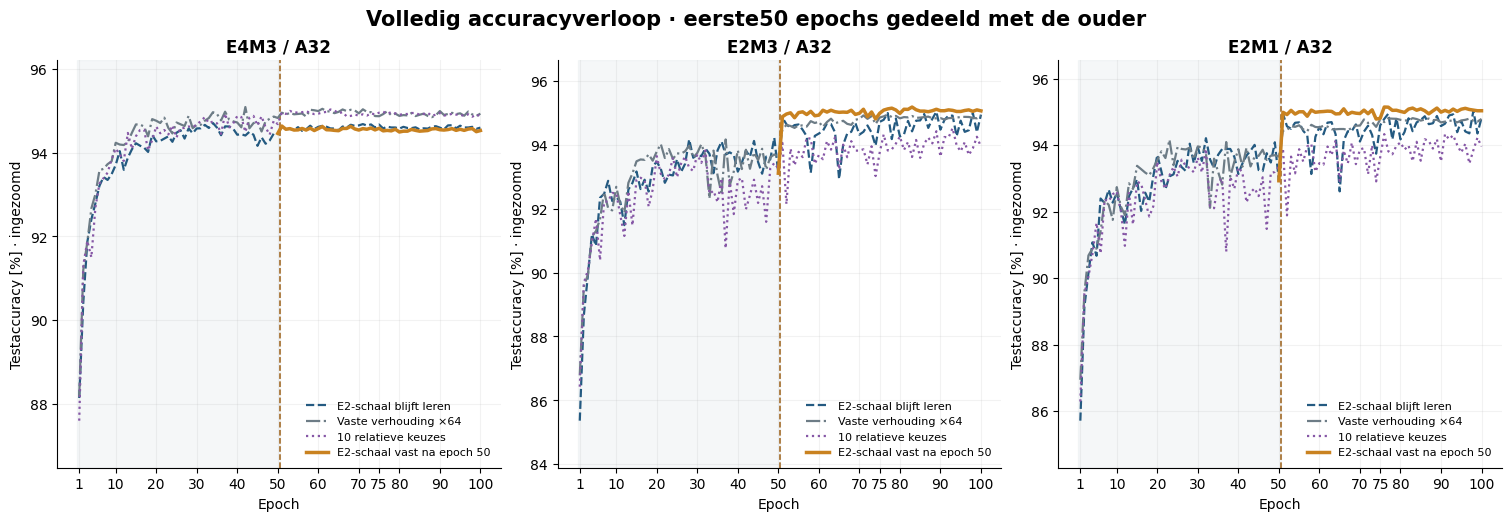

In [4]:
figures["accuracy_volledig"] = nb.plot_learning(run)
display(figures["accuracy_volledig"])
plt.close(figures["accuracy_volledig"])

### Detail: de nieuwe vertakking en haar doorleercontrole

Epoch 50 is het gezamenlijke vertrekpunt. Nieuwe punten komen uitsluitend uit daadwerkelijk uitgevoerde epochs 51–100. De historische controle wordt op hetzelfde beschikbare epochvenster getoond; bij een gedeeltelijke run verschijnen geen toekomstige punten.


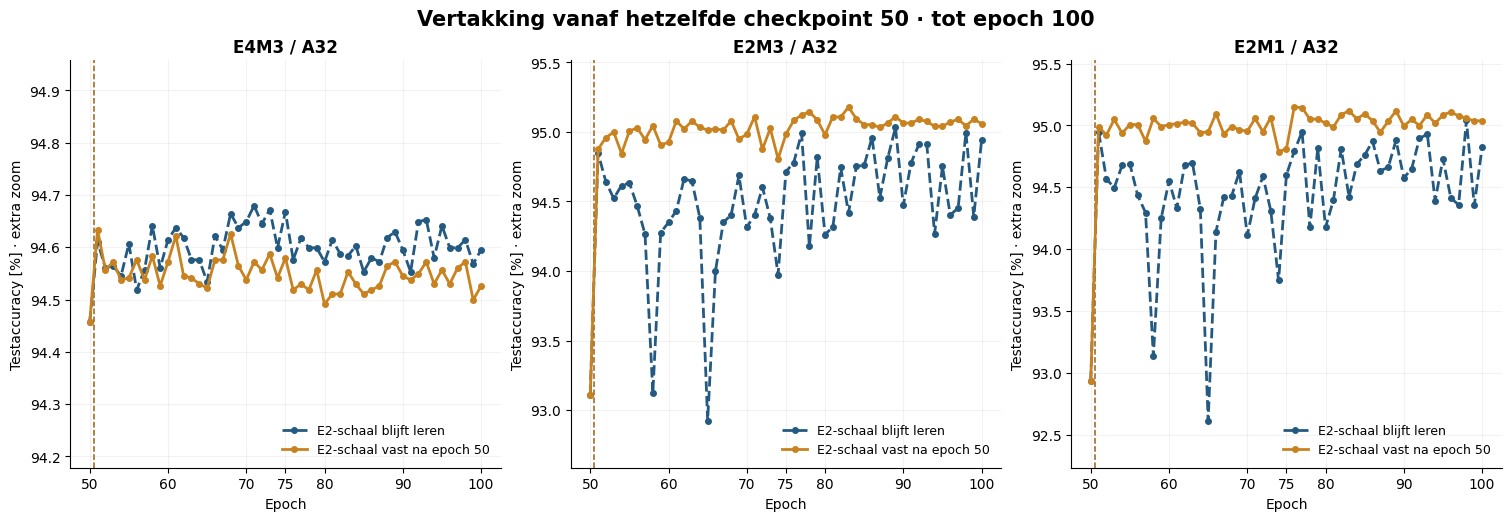

In [5]:
figures["accuracy_vertakking"] = nb.plot_final_window(run)
display(figures["accuracy_vertakking"])
plt.close(figures["accuracy_vertakking"])

## 3. Accuracy op hetzelfde eindpunt

**Varianten staan op de verticale as; accuracy op de horizontale as.** E4M3, E2M3 en E2M1 hebben elk een apart paneel. Elk punt is dezelfde cirkel en draagt zijn percentage. Een gedeeltelijke run toont haar werkelijk laatste epoch. Epoch 100 verschijnt pas wanneer de bijbehorende resultaten beschikbaar zijn.


,Variant,Variant_key,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,E2-schaal blijft leren,independent_full100_reference,100,gemeenschappelijk eindpunt,94.595114,24625,94.940842,24715,94.821758,24684
1,Vaste verhouding ×64,fixed_scale64_reference,100,gemeenschappelijk eindpunt,94.929318,24712,94.898586,24704,94.791026,24676
2,10 relatieve keuzes,relative_scale10_full100_reference,100,gemeenschappelijk eindpunt,94.871696,24697,93.934388,24453,93.961278,24460
3,E2-schaal vast na epoch 50,independent,100,gemeenschappelijk eindpunt,94.525968,24607,95.059926,24746,95.036878,24740


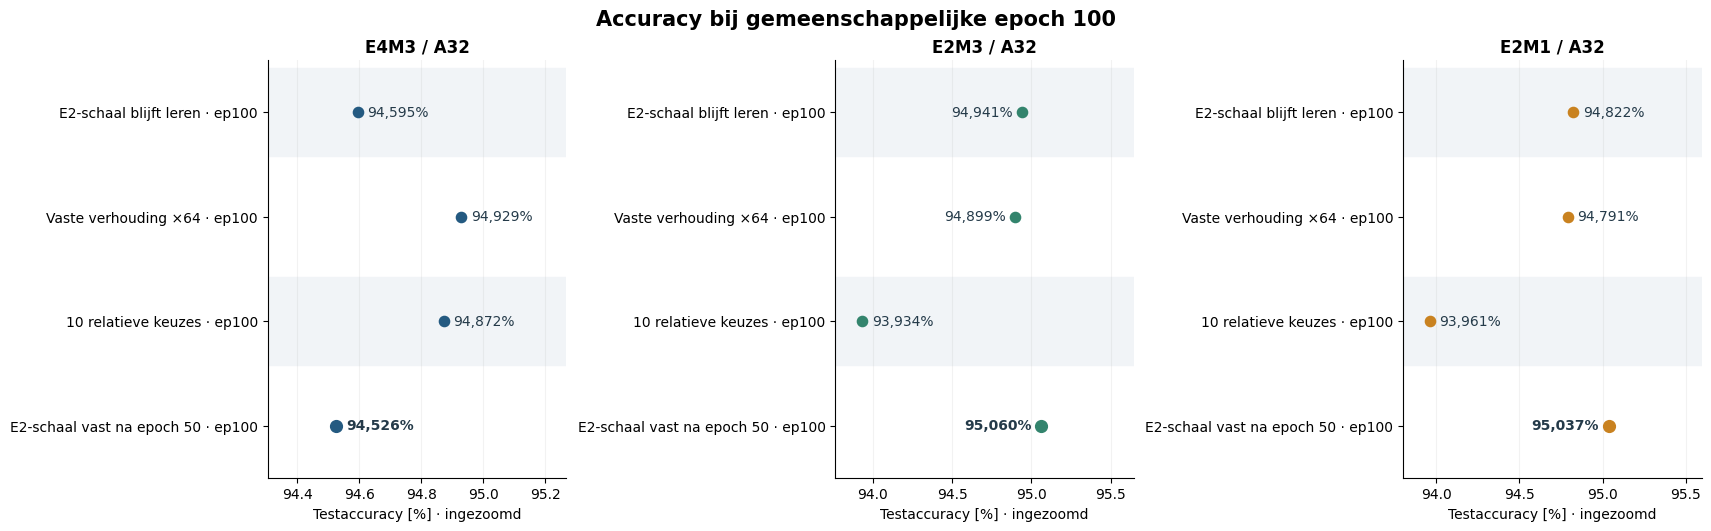

,Epoch,Referentie,Precisie,Freeze na50 [%],Referentie [%],Verschil [procentpunt],Verschil correct [beelden]
0,100,E2-schaal blijft leren,E4M3,94.525968,94.595114,-0.069146,-18
1,100,E2-schaal blijft leren,E2M3,95.059926,94.940842,0.119084,31
2,100,E2-schaal blijft leren,E2M1,95.036878,94.821758,0.215120,56
3,100,Vaste verhouding ×64,E4M3,94.525968,94.929318,-0.403350,-105
4,100,Vaste verhouding ×64,E2M3,95.059926,94.898586,0.161340,42
5,100,Vaste verhouding ×64,E2M1,95.036878,94.791026,0.245851,64
6,100,10 relatieve keuzes,E4M3,94.525968,94.871696,-0.345728,-90
7,100,10 relatieve keuzes,E2M3,95.059926,93.934388,1.125538,293
8,100,10 relatieve keuzes,E2M1,95.036878,93.961278,1.075599,280


In [6]:
display(nb.checkpoint_table(run, "last"))
figures["accuracy_eindpunt"] = nb.plot_checkpoints(run, "last")
display(figures["accuracy_eindpunt"])
plt.close(figures["accuracy_eindpunt"])
display(nb.difference_table(run))

## 4. Gemeenschappelijk checkpoint gekozen op de hoogste E4M3-accuracy

Voor elke variant wordt binnen **epochs 1–laatste** de eerste hoogste E4M3-testaccuracy gekozen. De drie precisies worden vervolgens op diezelfde epoch getoond. De gekozen epoch staat bij de variant. Dit checkpoint kan vóór de freeze liggen; dan bevat het nog geen effect van de nieuwe ingreep.

,Variant,Variant_key,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,E2-schaal blijft leren,independent_full100_reference,34,eerste beste E4 in1..laatste,94.706515,24654,93.108482,24238,93.312077,24291
1,Vaste verhouding ×64,fixed_scale64_reference,42,eerste beste E4 in1..laatste,95.086816,24753,93.842194,24429,93.922864,24450
2,10 relatieve keuzes,relative_scale10_full100_reference,63,eerste beste E4 in1..laatste,95.029195,24738,93.846036,24430,93.700061,24392
3,E2-schaal vast na epoch 50,independent,34,eerste beste E4 in1..laatste,94.706515,24654,93.108482,24238,93.312077,24291


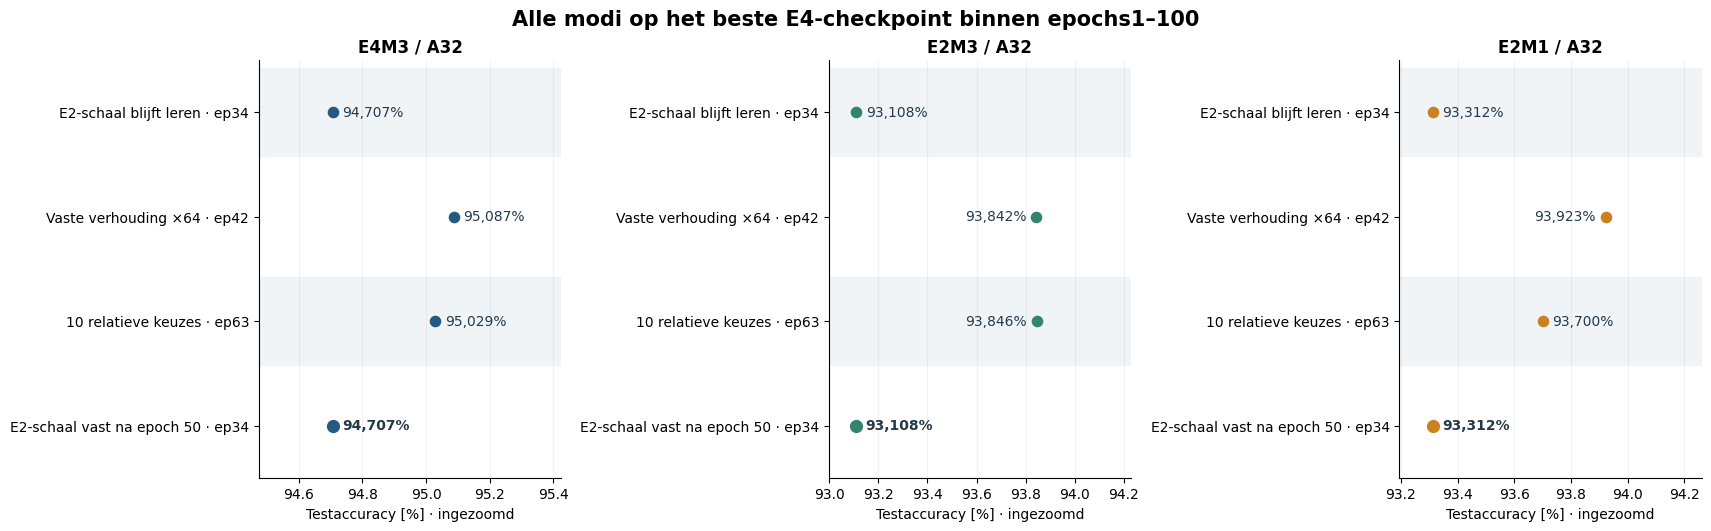

In [7]:
display(nb.checkpoint_table(run, "best"))
figures["accuracy_beste_E4_geheel"] = nb.plot_checkpoints(run, "best")
display(figures["accuracy_beste_E4_geheel"])
plt.close(figures["accuracy_beste_E4_geheel"])

### Aanvullend: beste E4M3 uitsluitend binnen de nieuwe epochs

Deze selectie gebruikt **epochs 51–laatste**. Zij voorkomt dat een sterk checkpoint uit de gedeelde voorgeschiedenis alle branchverschillen verbergt. Dit is een aanvullende diagnose; de eerder afgesproken globale selectie blijft hierboven staan. Ook hier komen alle drie de modi uit hetzelfde gekozen checkpoint.

,Variant,Variant_key,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,E2-schaal blijft leren,independent_full100_reference,71,eerste beste E4 in51..laatste,94.679625,24647,94.403042,24575,94.410725,24577
1,Vaste verhouding ×64,fixed_scale64_reference,61,eerste beste E4 in51..laatste,95.044561,24742,94.556699,24615,94.583589,24622
2,10 relatieve keuzes,relative_scale10_full100_reference,63,eerste beste E4 in51..laatste,95.029195,24738,93.846036,24430,93.700061,24392
3,E2-schaal vast na epoch 50,independent,51,eerste beste E4 in51..laatste,94.633528,24635,94.875538,24698,94.990781,24728


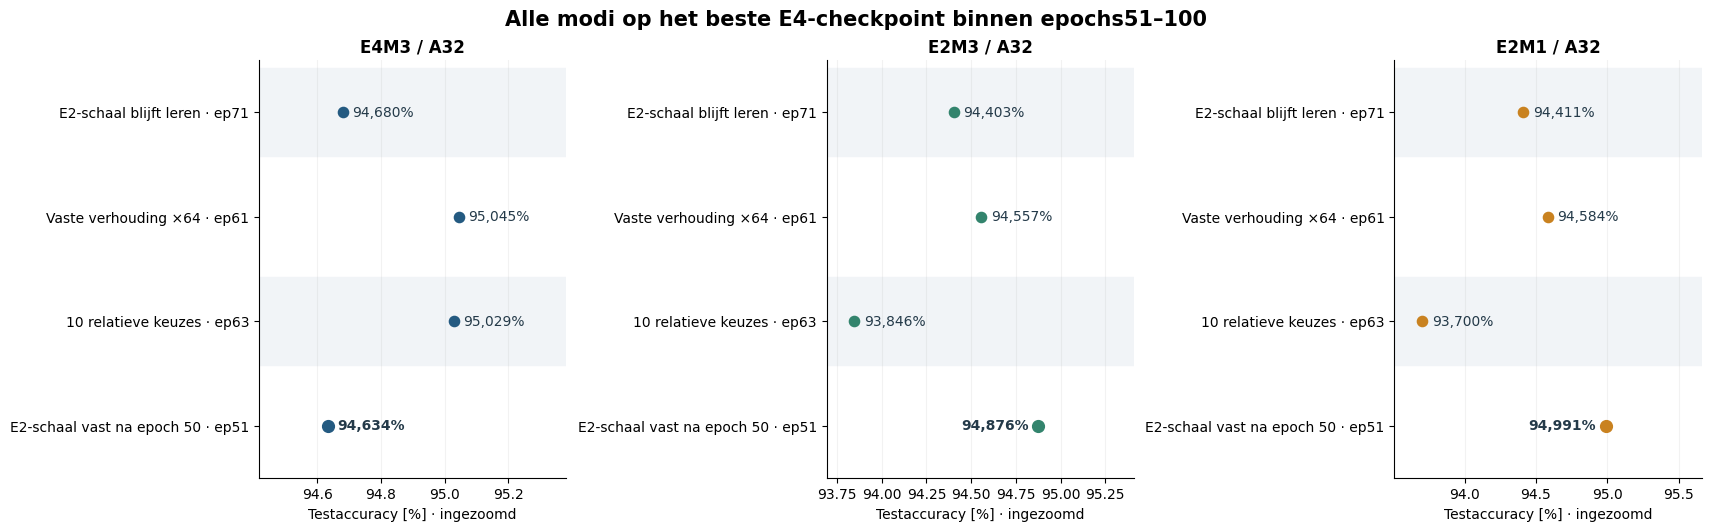

In [8]:
display(nb.checkpoint_table(run, "branch_best"))
figures["accuracy_beste_E4_vertakking"] = nb.plot_checkpoints(run, "branch_best")
display(figures["accuracy_beste_E4_vertakking"])
plt.close(figures["accuracy_beste_E4_vertakking"])

## 5. Bewijs dat de absolute E2-schaal vast blijft

De lezer controleert de continue φ-waarden en de afgeronde absolute E2-exponenten tegen epoch 50. De runner controleert tijdens de nieuwe updates bovendien dat de schaal-Adam-toestand niet verandert en dat φ geen opgeslagen gradient krijgt. Een veranderende geobserveerde verhouding E2/E4 kan wél optreden door beweging van E4.

,Freezecontrole,Waarde
0,Nieuwe freeze-epochs,50
1,Groepen met gewijzigde continue φ sinds50,0
2,Groepen met andere absolute E2-exponent sinds50,0
3,E2-wisselgebeurtenissen tijdens nieuwe epochs,0
4,Groepen met andere E4-bronexponent sinds50,217
5,Groepen met andere verhouding E2/E4 sinds50,217


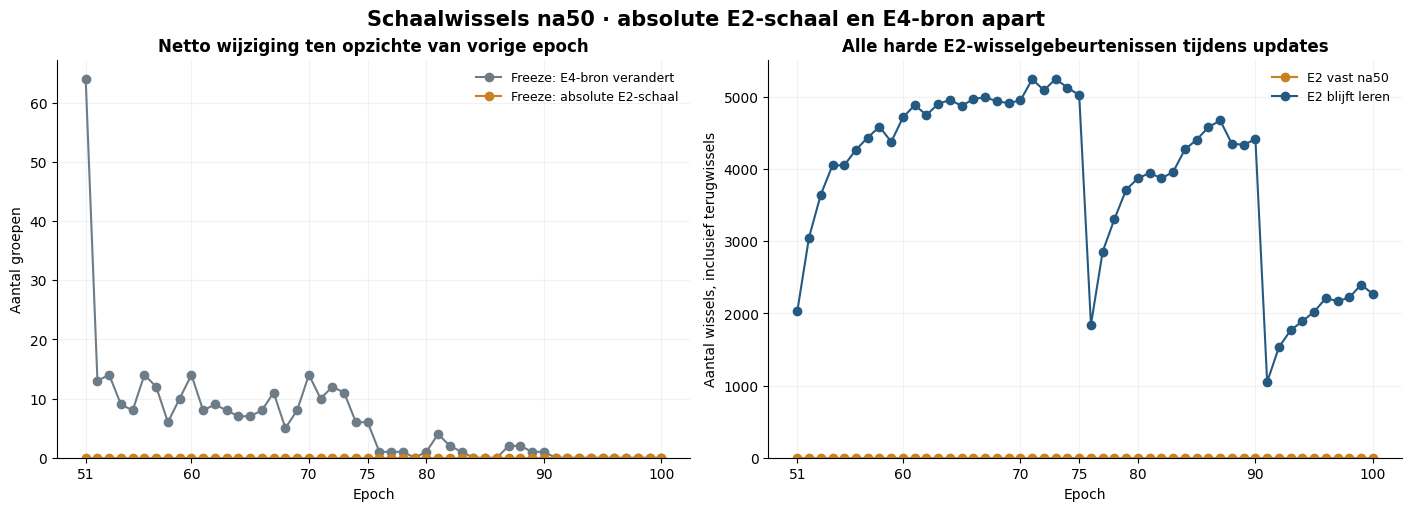

In [9]:
display(nb.freeze_evidence_table(run))
figures["freeze_wissels"] = nb.plot_freeze_comparison(run)
display(figures["freeze_wissels"])
plt.close(figures["freeze_wissels"])

### Absolute schaalverdeling en geobserveerde verhouding

Links staan absolute E2-exponenten; rechts staat de achteraf berekende verhouding tot E4. De verhouding is geen geleerd keuzemenu. De oude E2-schaal kan daardoor gelijk blijven terwijl het rechter histogram verschuift.

,Epoch,Geobserveerde Δ=e₂−e₄,Verhouding S₂/S₄,Groepen,Aandeel [%]
0,50,1,×2,1,0.024510
1,50,2,×4,348,8.529412
2,50,3,×8,2364,57.941176
3,50,4,×16,1259,30.857843
4,50,5,×32,63,1.544118
5,50,6,×64,37,0.906863
6,50,7,×128,8,0.196078


,Epoch,Geobserveerde Δ=e₂−e₄,Verhouding S₂/S₄,Groepen,Aandeel [%]
0,100,1,×2,1,0.024510
1,100,2,×4,411,10.073529
2,100,3,×8,2442,59.852941
3,100,4,×16,1123,27.524510
4,100,5,×32,63,1.544118
5,100,6,×64,33,0.808824
6,100,7,×128,7,0.171569


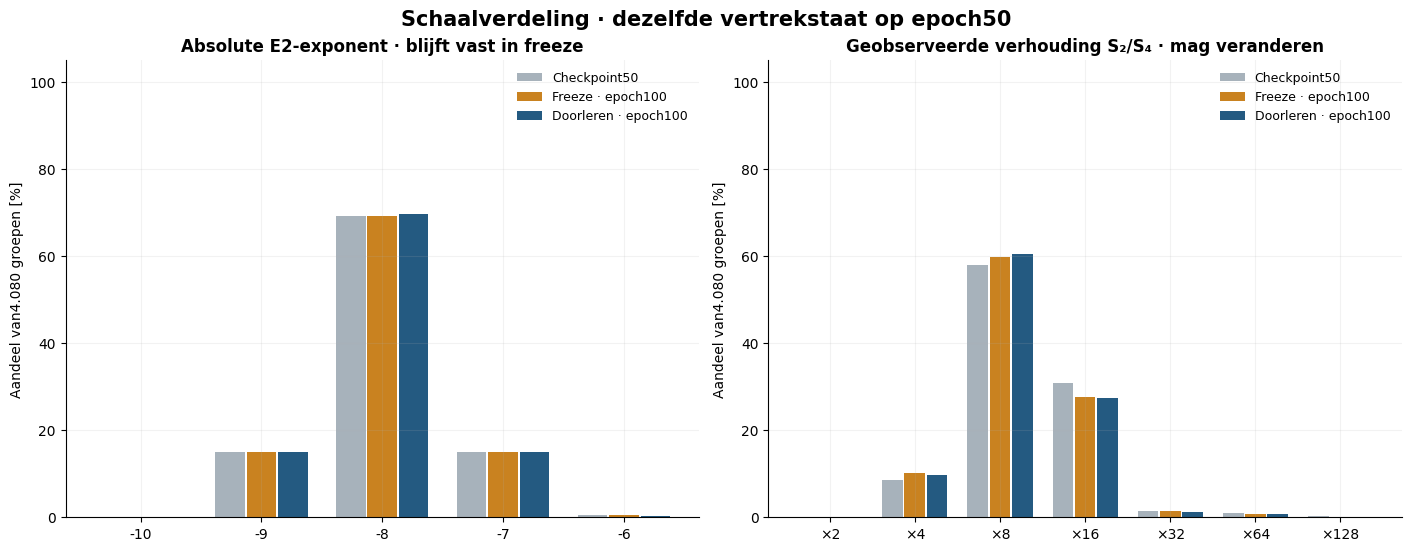

In [10]:
display(nb.scale_distribution_table(run, epoch=50) if run.last_epoch is not None else nb.scale_distribution_table(run))
display(nb.scale_distribution_table(run))
figures["schaalverdelingen"] = nb.plot_scale_distributions(run)
display(figures["schaalverdelingen"])
plt.close(figures["schaalverdelingen"])

### Verdeling en gemiddelden gedurende het volledige traject

Epochs 0–50 zijn afkomstig uit de ouder. Vanaf epoch 51 moet de absolute E2-verdeling identiek blijven; de verhouding en E4-bronschaal mogen veranderen.

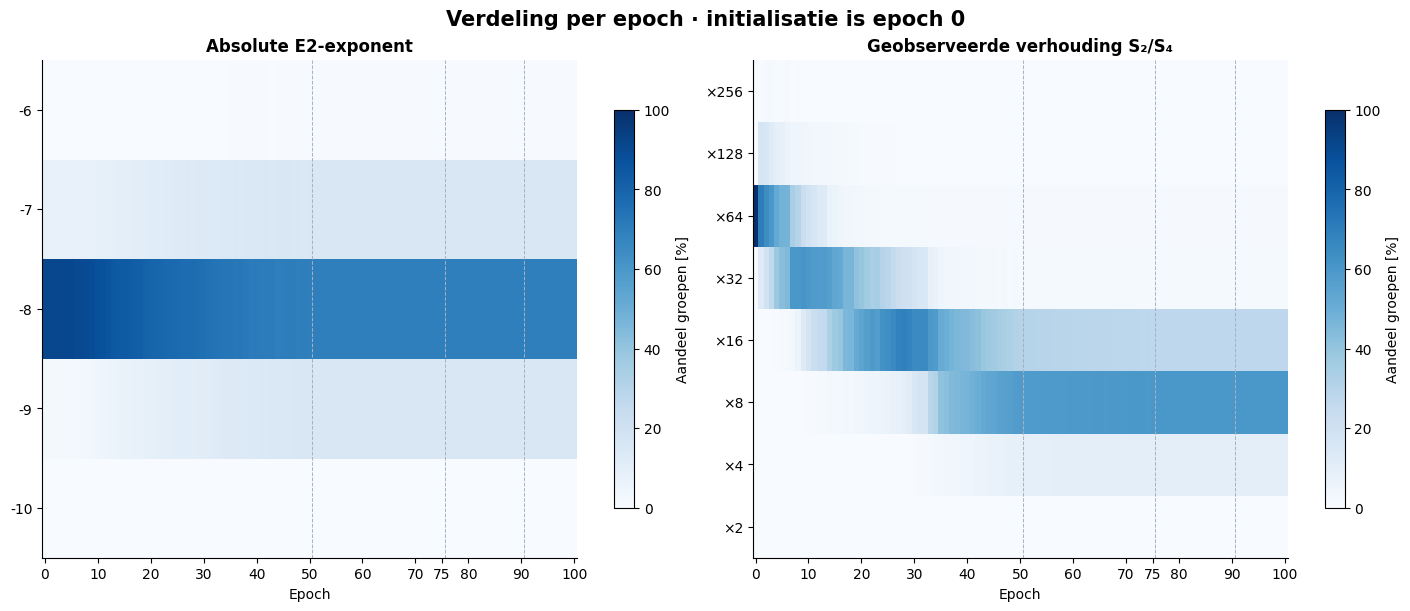

,layer,Groepen,phi_min,phi_gemiddeld,phi_max,E2_exponent_min,E2_exponent_max,geobserveerde_delta_min,geobserveerde_delta_max
0,layers.3,64,-7.728895,-6.978854,-6.480861,-8,-6,3,5
1,layers.6,80,-7.784478,-7.019494,-6.487420,-8,-6,3,5
2,layers.10,160,-7.595430,-6.996291,-6.489651,-8,-6,3,5
3,layers.13,288,-8.541617,-7.999336,-7.492340,-9,-7,2,4
4,layers.16,288,-8.529054,-8.021720,-7.493786,-9,-7,2,4
5,layers.20,3200,-9.716574,-7.993155,-6.320923,-10,-6,1,7


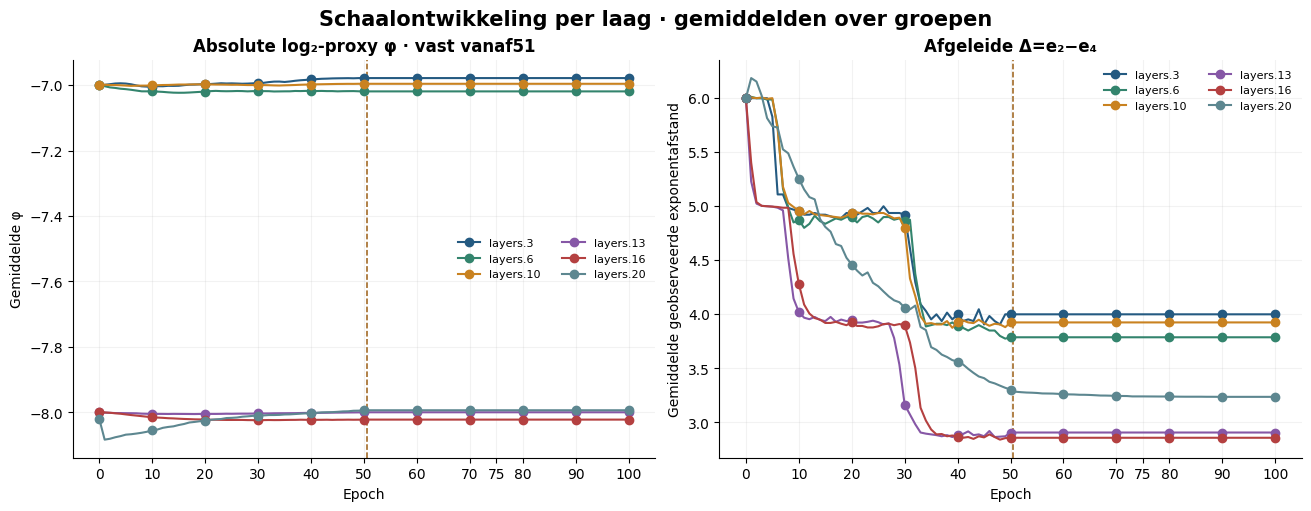

In [11]:
figures["schaalevolutie"] = nb.plot_scale_evolution(run)
display(figures["schaalevolutie"])
plt.close(figures["schaalevolutie"])
display(nb.scale_layer_table(run))
figures["schalen_per_laag"] = nb.plot_scale_by_layer(run)
display(figures["schalen_per_laag"])
plt.close(figures["schalen_per_laag"])

### Wissels, gradients en grensprojecties

Een wisselgebeurtenis kan herhaald dezelfde groep betreffen. Dat aantal is niet hetzelfde als het aantal groepen met een andere eindwaarde. Vanaf epoch 51 zijn de schaalgradientkolommen in het rapport nul als conventie voor **uitgeschakeld**; `φ.grad` is afwezig. Dit is geen gemeten nulgradient en geen bewijs van convergentie.

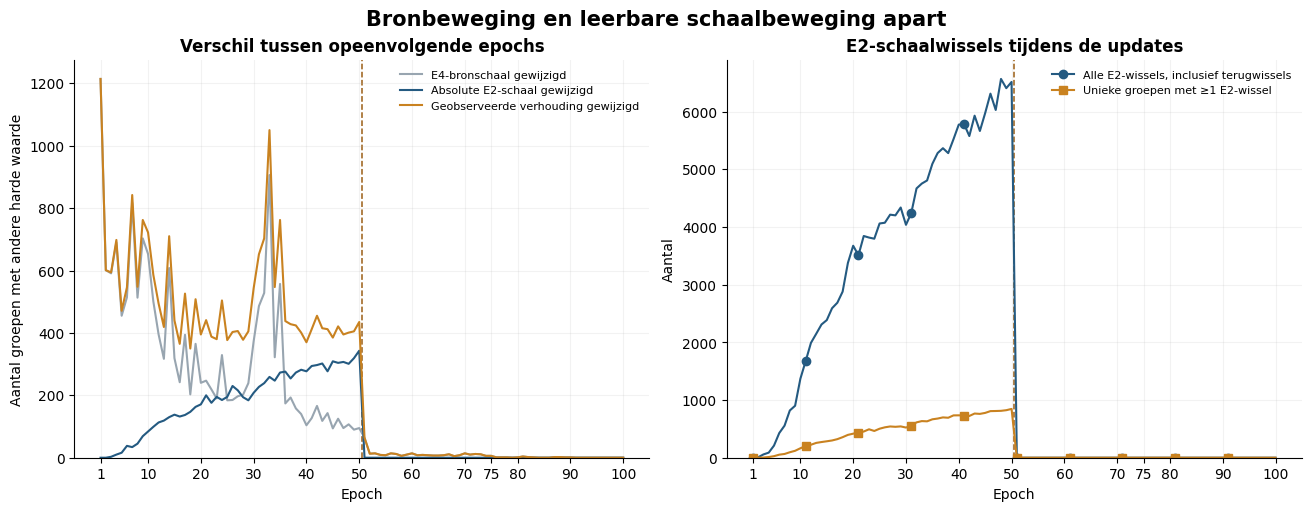

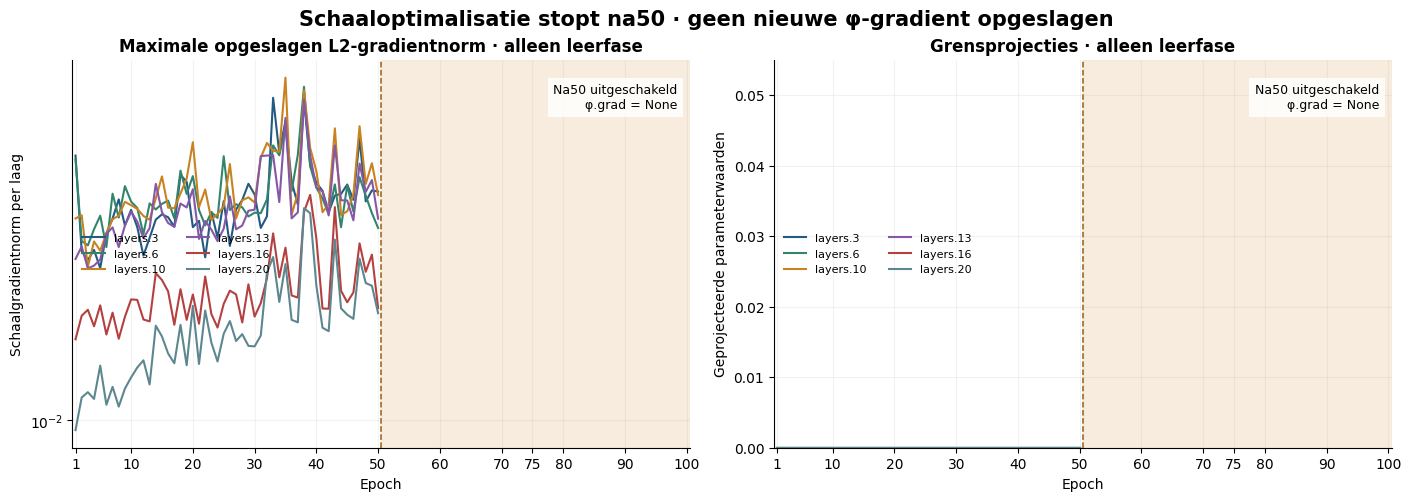

In [12]:
figures["schaalveranderingen_volledig"] = nb.plot_scale_changes(run)
display(figures["schaalveranderingen_volledig"])
plt.close(figures["schaalveranderingen_volledig"])
figures["schaaloptimalisatie"] = nb.plot_scale_gradients(run)
display(figures["schaaloptimalisatie"])
plt.close(figures["schaaloptimalisatie"])

## 6. Opslag en bijkomende kosten

De freeze verandert de compacte representatie niet: er blijven één E4-schaalbyte en één onafhankelijke E2-schaalbyte per groep nodig. Voor 4.080 groepen is dat **8.160 bytes schaalmetadata**: +4.080 bytes tegenover vaste ×64 en +2.040 bytes tegenover vier bits voor tien relatieve keuzes.

De tabel onderscheidt compacte codes en schaalmetadata van de nominale trainingshulppayload. In de freezecheckpoint blijven FP32-proxies en twee Adam-momenten bewaard voor herkomst en hervatten; hun opgeslagen gradients zijn afwezig. Dat betekent niet dat tijdelijke berekeningen of alle frameworkoverhead verdwijnen. Randlagen, BN, bestandheaders en allocatoroverhead staan niet in de berekende MX-payload.

**Opslag bewijst geen DRAM-transfer-, latency- of energiewinst.** Die vereisen een afzonderlijke meting met vastgelegde caching, packing en hardware. Er blijven drie precisiepasses per minibatch.

,Variant,Groepen,E4-schaalbytes,Extra schaal/keuzebytes,Totaal schaalinformatie [bytes],Schaalinformatie [bit per B32-positie],"E4-codes + schaalinformatie, zes MX-lagen [bytes]",Nominale bewaarde FP32-schaalhulppayload [bytes]
0,Vaste ×64,4080,4080,0,4080,0.250,134640,0
1,10 relatieve keuzes,4080,4080,2040,6120,0.375,136680,65280
2,E2 blijft leren,4080,4080,4080,8160,0.500,138720,65280
3,E2 vast na50,4080,4080,4080,8160,0.500,138720,48960


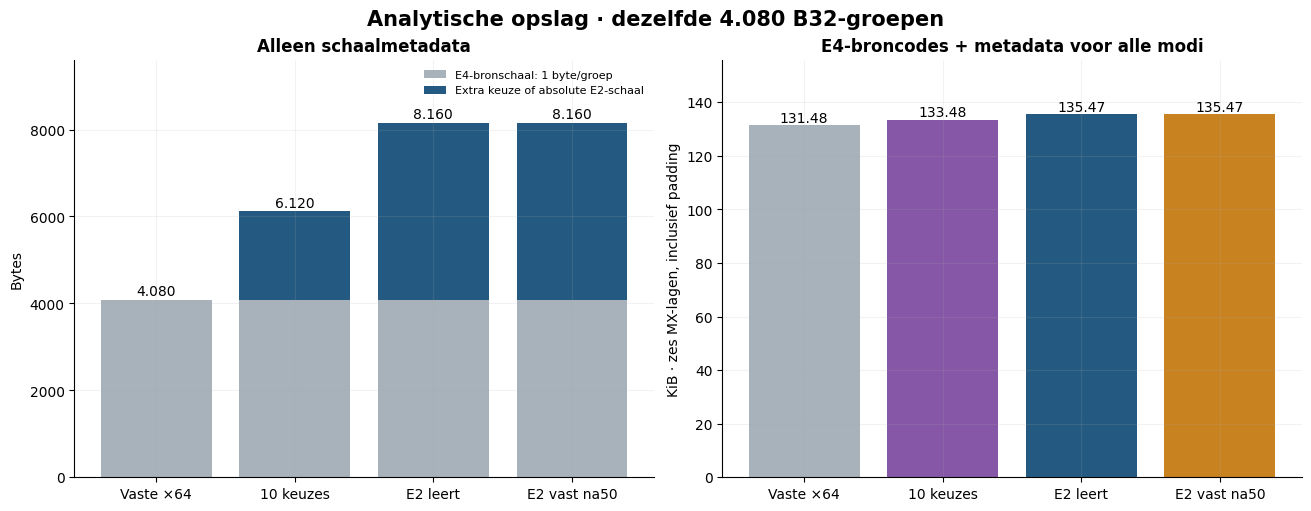

,Rol,Epoch,Precisie,Bestand,Containerbytes,Gewichten exact gereconstrueerd,MX-masters afwezig,FP32-schaalproxy afwezig,Afgeleid uit opgeslagen bron,Masters gelezen bij afleiding,Bron-SHA256
0,best_E4M3_test,34,E4M3,mx_source_MXFP8_E4M3_best.pt,202521,True,True,True,False,False,98655a88fee23f7efe73de73bd57834ec9bf54682007f9...
1,best_E4M3_test,34,E2M3,mx_derived_MXFP6_E2M3_best.pt,170585,True,True,True,True,False,98655a88fee23f7efe73de73bd57834ec9bf54682007f9...
2,best_E4M3_test,34,E2M1,mx_derived_MXFP4_E2M1_best.pt,137945,True,True,True,True,False,98655a88fee23f7efe73de73bd57834ec9bf54682007f9...
3,last_epoch,100,E4M3,mx_source_MXFP8_E4M3_last.pt,202521,True,True,True,False,False,636bececacb8008be40aa341d55abcfdfbc80a7325fe71...
4,last_epoch,100,E2M3,mx_derived_MXFP6_E2M3_last.pt,170585,True,True,True,True,False,636bececacb8008be40aa341d55abcfdfbc80a7325fe71...
5,last_epoch,100,E2M1,mx_derived_MXFP4_E2M1_last.pt,137945,True,True,True,True,False,636bececacb8008be40aa341d55abcfdfbc80a7325fe71...
6,branch_best_E4M3_test,51,E4M3,mx_source_MXFP8_E4M3_branch_best.pt,202521,True,True,True,False,False,0b4df113a63c1bb528d1ea9e5ab75ba21a1fa2ff80e756...
7,branch_best_E4M3_test,51,E2M3,mx_derived_MXFP6_E2M3_branch_best.pt,170585,True,True,True,True,False,0b4df113a63c1bb528d1ea9e5ab75ba21a1fa2ff80e756...
8,branch_best_E4M3_test,51,E2M1,mx_derived_MXFP4_E2M1_branch_best.pt,137945,True,True,True,True,False,0b4df113a63c1bb528d1ea9e5ab75ba21a1fa2ff80e756...


In [13]:
display(nb.storage_cost_table(run))
figures["opslagkosten"] = nb.plot_storage_cost(run)
display(figures["opslagkosten"])
plt.close(figures["opslagkosten"])
display(nb.export_table(run))

## 7. Tijd van alleen de nieuw uitgevoerde epochs

De eerste 50 epochs worden niet opnieuw uitgevoerd en tellen niet mee als nieuwe looptijd van deze run. Tot epoch 100 is bereikt, wordt een eventuele resterende duur als schatting gemarkeerd. Na voltooiing staat hier de **gemeten tijd van alle 50 nieuwe epochs**; de historische tijd van epochs 1–50 blijft afzonderlijk herkenbaar. De optelsom beschrijft een traject met hergebruikte voorgeschiedenis, geen training van 100 nieuwe epochs.


**Nieuw gemeten:** 57.78 minuten voor 50 freeze-epochs. De 53.20 minuten van epochs 1–50 zijn overgenomen uit de ouder en zijn hier niet opnieuw uitgevoerd. **Alle 50 nieuwe epochs tot en met epoch 100 zijn gemeten; er is geen resterende tijdprojectie.** De historische en nieuwe epochtijden tellen samen op tot 110.98 minuten. Dat gecombineerde getal beschrijft het volledige traject met hergebruikte voorgeschiedenis, niet 100 opnieuw uitgevoerde epochs. Voorbereiding, gegevens laden en laatste rapportexport vallen buiten de epochtijden.

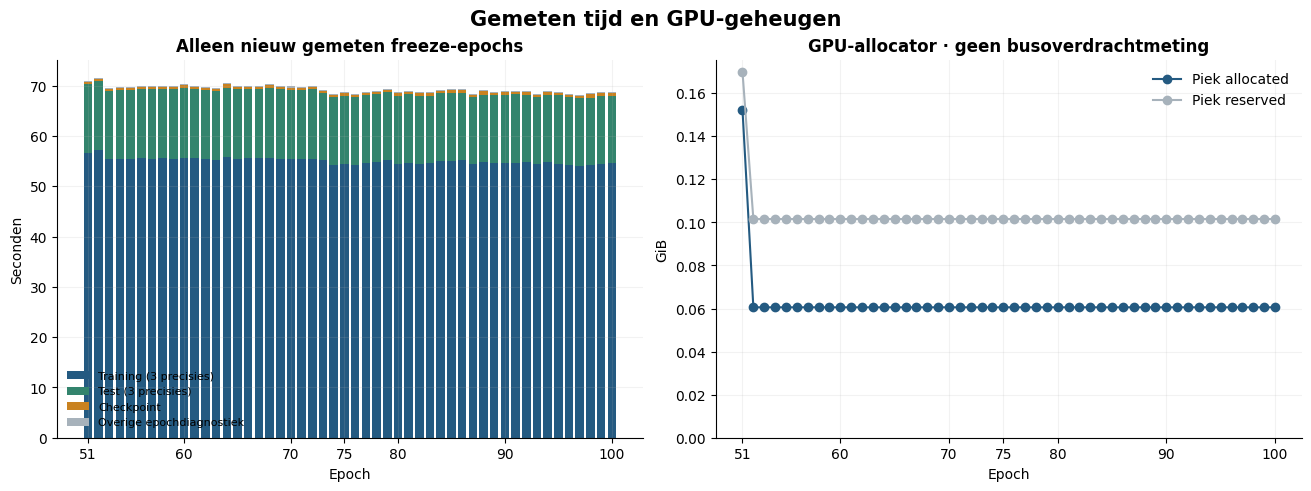

In [14]:
display(Markdown(nb.timing_markdown(run)))
figures["looptijd"] = nb.plot_timing(run)
display(figures["looptijd"])
plt.close(figures["looptijd"])

## 8. Softwarecontrole en interpretatie

Een technische PASS bevestigt correcte uitvoering, geen accuracywinst. Beoordeel dezelfde eindepoch, de gemeenschappelijke E4-selectie, het nieuwe venster vanaf epoch 51, de absolute E2-wissels en de accuracystabiliteit.

De vergelijking betreft één vertakking van één seed. Opeenvolgende epochs zijn geen onafhankelijke herhalingen. De GPU-backend garandeert geen bit-exacte herhaling; deze nieuwe start hoeft de eerdere vijfepochpilot daarom niet exact te reproduceren. Een resultaat op epoch 100 kan alleen worden geconcludeerd uit de werkelijk voltooide nieuwe run.


In [15]:
display(nb.audit_table(run))
display(nb.diagnostics_table(run))

,Controle,Opgeslagen resultaat / analyse
0,Rapportstatus,PASS
1,Metrics consistent met geschiedenis,True
2,Schaalstaten en bitexponenten consistent,True
3,Checkpointselectie gecontroleerd,True
4,Historische referenties geverifieerd,True
5,FP32-masters en Adam-momenten,True
6,Eén E4-bron per laag en minibatch,True
7,E2M1-schaal identiek aan E2M3,True
8,Cache leeg vóór optimizerupdates,True
9,Evaluatie zonder optimizerupdates,True


,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 9. Optioneel figuren bewaren

Zet `SAVE_FIGURES = True` in de parametercel om afgeleide PNG- en PDF-figuren naar een nieuwe map te schrijven. Ruwe resultaten en bestaande figuren worden niet overschreven. De standaardinstelling bewaart niets.

In [16]:
if SAVE_FIGURES:
    figure_directory = nb.save_figures(figures, run)
    display(Markdown(f"Figuren opgeslagen in: `{figure_directory}`"))
else:
    display(Markdown("Figuren zijn alleen weergegeven; `SAVE_FIGURES = False`."))

Figuren zijn alleen weergegeven; `SAVE_FIGURES = False`.